# **PEC 2 - Redes Neuronales Densas (MLP) y Parkinson**
##  Alberto Torrejón Aquino



La enfermedad de Parkinson es un trastorno neurodegenerativo crónico caracterizado por la pérdida progresiva de neuronas dopaminérgicas, lo que provoca un deterioro gradual de funciones motoras y no motoras. Entre los síntomas que se ven alterados desde etapas tempranas se encuentra **la voz**, cuya calidad, estabilidad y variabilidad pueden verse afectadas por la progresión de la enfermedad. Esta relación hace que el análisis acústico sea un recurso útil para el seguimiento remoto de los pacientes.

En esta actividad se trabaja con un conjunto de datos procedente de un estudio de telemonitorización, en el que se registraron 5.875 muestras de voz obtenidas automáticamente en los hogares de 42 personas con Parkinson en fase inicial. Cada registro incluye, además del identificador del paciente, edad, sexo y medidas clínicas como motor_UPDRS y total_UPDRS, un conjunto de 16 características biomédicas derivadas del análisis de la voz (jitter, shimmer, HNR, RPDE, DFA, PPE, entre otras). Estas características buscan capturar distintas dimensiones acústicas relacionadas con la inestabilidad de la frecuencia, la variabilidad de la amplitud y la complejidad dinámica del sistema vocal.

El objetivo de la práctica es construir y evaluar modelos de redes neuronales profundas densas (MLP) capaces de predecir la severidad del Parkinson a partir exclusivamente de las 16 medidas acústicas de la voz. Para ello, se transforma la variable total_UPDRS en una etiqueta binaria de severidad, se realiza la preparación del conjunto de datos y se comparan dos arquitecturas distintas de MLP. A partir de su rendimiento y de las métricas obtenidas, se discuten las fortalezas, limitaciones y posibles mejoras de los modelos implementados.



In [48]:

# Importación de librerías necesarias para el proyecto

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

from tensorflow import keras
from tensorflow.keras import layers


# **1. Carga de datos**



In [49]:
# Carga de datos de registros

# Convertimos a Data frame para poder tratar con ellos

ruta_fichero = "/content/parkinsons_updrs.data"
df = pd.read_csv(ruta_fichero)

# Inspección básica
df.head()


,subject#,age,sex,test_time,motor_UPDRS,total_UPDRS,Jitter(%),Jitter(Abs),Jitter:RAP,Jitter:PPQ5,...,Shimmer(dB),Shimmer:APQ3,Shimmer:APQ5,Shimmer:APQ11,Shimmer:DDA,NHR,HNR,RPDE,DFA,PPE
0,1,72,0,5.6431,28.199,34.398,0.00662,0.000034,0.00401,0.00317,...,0.230,0.01438,0.01309,0.01662,0.04314,0.014290,21.640,0.41888,0.54842,0.16006
1,1,72,0,12.6660,28.447,34.894,0.00300,0.000017,0.00132,0.00150,...,0.179,0.00994,0.01072,0.01689,0.02982,0.011112,27.183,0.43493,0.56477,0.10810
2,1,72,0,19.6810,28.695,35.389,0.00481,0.000025,0.00205,0.00208,...,0.181,0.00734,0.00844,0.01458,0.02202,0.020220,23.047,0.46222,0.54405,0.21014
3,1,72,0,25.6470,28.905,35.810,0.00528,0.000027,0.00191,0.00264,...,0.327,0.01106,0.01265,0.01963,0.03317,0.027837,24.445,0.48730,0.57794,0.33277
4,1,72,0,33.6420,29.187,36.375,0.00335,0.000020,0.00093,0.00130,...,0.176,0.00679,0.00929,0.01819,0.02036,0.011625,26.126,0.47188,0.56122,0.19361


In [50]:
# Dimensiones del dataset
print("Número de filas:", df.shape[0])
print("Número de columnas:", df.shape[1])

# Información de tipos de datos y valores no nulos para ver la limpieza necesaria
df.info()


Número de filas: 5875
Número de columnas: 22
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5875 entries, 0 to 5874
Data columns (total 22 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   subject#       5875 non-null   int64  
 1   age            5875 non-null   int64  
 2   sex            5875 non-null   int64  
 3   test_time      5875 non-null   float64
 4   motor_UPDRS    5875 non-null   float64
 5   total_UPDRS    5875 non-null   float64
 6   Jitter(%)      5875 non-null   float64
 7   Jitter(Abs)    5875 non-null   float64
 8   Jitter:RAP     5875 non-null   float64
 9   Jitter:PPQ5    5875 non-null   float64
 10  Jitter:DDP     5875 non-null   float64
 11  Shimmer        5875 non-null   float64
 12  Shimmer(dB)    5875 non-null   float64
 13  Shimmer:APQ3   5875 non-null   float64
 14  Shimmer:APQ5   5875 non-null   float64
 15  Shimmer:APQ11  5875 non-null   float64
 16  Shimmer:DDA    5875 non-null   float64
 17  NHR    

En este caso, vemos que no tenemos valores nulos y que nuestras columnas tienen los valores en los que podemos trabajar, por lo que no necesitan limpieza estos datos. Para estudios de MLP, es muy importante que tengamos en cuenta la validez de los datos que estamos estudiando. Se suele decir ***"Garbage in, garbage out"***, dando a entender que la calidad del modelo nunca puede superar la calidad de los datos con los que vamos a entrenar


# **2. Descriptiva univariante**



In [51]:
# Estadística descriptiva univariante

# transponemos para ver variables en filas y le aplicamos describe para ver sus estadísticos
desc = df.describe().T
desc

,count,mean,std,min,25%,50%,75%,max
subject#,5875.0,21.494128,12.372279,1.000000,10.000000,22.000000,33.000000,42.000000
age,5875.0,64.804936,8.821524,36.000000,58.000000,65.000000,72.000000,85.000000
sex,5875.0,0.317787,0.465656,0.000000,0.000000,0.000000,1.000000,1.000000
test_time,5875.0,92.863722,53.445602,-4.262500,46.847500,91.523000,138.445000,215.490000
motor_UPDRS,5875.0,21.296229,8.129282,5.037700,15.000000,20.871000,27.596500,39.511000
total_UPDRS,5875.0,29.018942,10.700283,7.000000,21.371000,27.576000,36.399000,54.992000
Jitter(%),5875.0,0.006154,0.005624,0.000830,0.003580,0.004900,0.006800,0.099990
Jitter(Abs),5875.0,0.000044,0.000036,0.000002,0.000022,0.000035,0.000053,0.000446
Jitter:RAP,5875.0,0.002987,0.003124,0.000330,0.001580,0.002250,0.003290,0.057540
Jitter:PPQ5,5875.0,0.003277,0.003732,0.000430,0.001820,0.002490,0.003460,0.069560


In [52]:
cols_interes = [
    "total_UPDRS",
    "Jitter(%)",
    "Jitter(Abs)",
    "Jitter:RAP",
    "Jitter:PPQ5",
    "Jitter:DDP",
    "Shimmer",
    "Shimmer(dB)",
    "Shimmer:APQ3",
    "Shimmer:APQ5",
    "Shimmer:APQ11",
    "Shimmer:DDA",
    "NHR",
    "HNR",
    "RPDE",
    "DFA",
    "PPE"
]

desc_interes = df[cols_interes].describe().T
desc_interes


,count,mean,std,min,25%,50%,75%,max
total_UPDRS,5875.0,29.018942,10.700283,7.000000,21.371000,27.576000,36.399000,54.992000
Jitter(%),5875.0,0.006154,0.005624,0.000830,0.003580,0.004900,0.006800,0.099990
Jitter(Abs),5875.0,0.000044,0.000036,0.000002,0.000022,0.000035,0.000053,0.000446
Jitter:RAP,5875.0,0.002987,0.003124,0.000330,0.001580,0.002250,0.003290,0.057540
Jitter:PPQ5,5875.0,0.003277,0.003732,0.000430,0.001820,0.002490,0.003460,0.069560
Jitter:DDP,5875.0,0.008962,0.009371,0.000980,0.004730,0.006750,0.009870,0.172630
Shimmer,5875.0,0.034035,0.025835,0.003060,0.019120,0.027510,0.039750,0.268630
Shimmer(dB),5875.0,0.310960,0.230254,0.026000,0.175000,0.253000,0.365000,2.107000
Shimmer:APQ3,5875.0,0.017156,0.013237,0.001610,0.009280,0.013700,0.020575,0.162670
Shimmer:APQ5,5875.0,0.020144,0.016664,0.001940,0.010790,0.015940,0.023755,0.167020


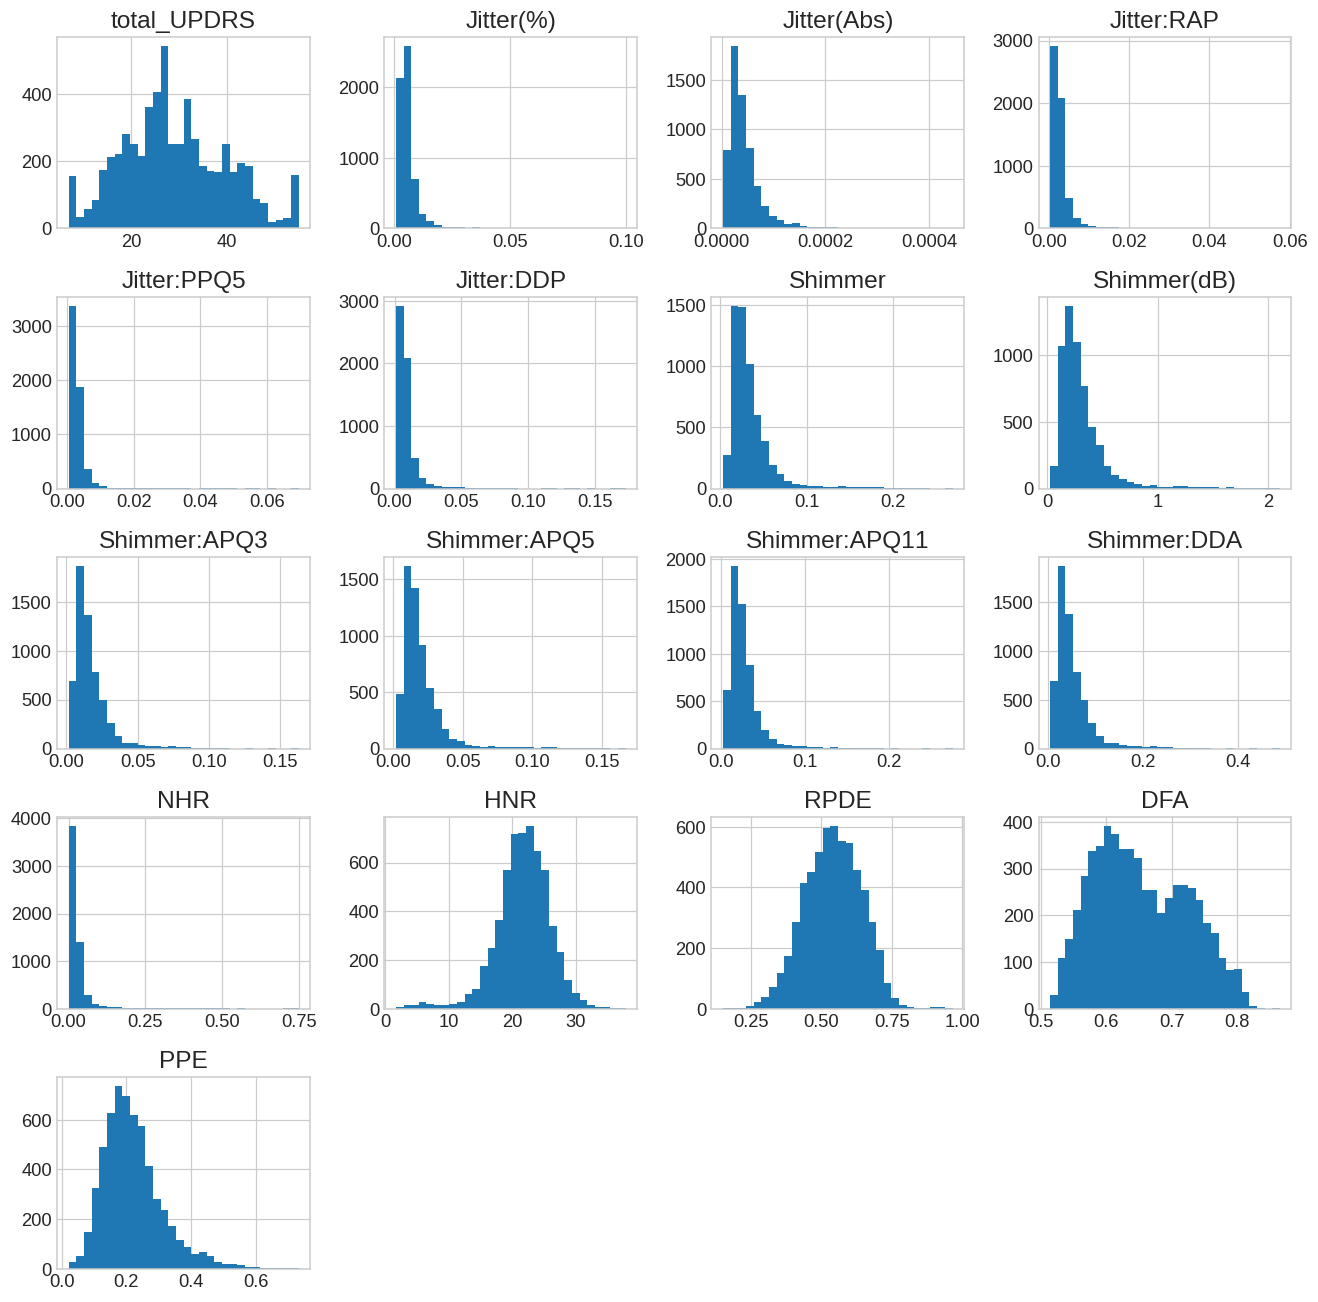

In [72]:
# Histogramas de las variables de interés

df[cols_interes].hist(bins=30, figsize=(12, 12))
plt.tight_layout()
plt.show()




A partir del análisis descriptivo univariante y la visualización mediante histogramas de las 16 variables biomédicas de voz, se observa que la mayoría presentan distribuciones altamente asimétricas, con valores muy concentrados cerca de cero y colas largas hacia la derecha. Po ello, antes de aplicar algoritmos de aprendizaje automático, es necesario realizar un proceso de normalización, de forma que todas las variables queden expresadas en una escala comparable


# **3. Estandarizar mediante la transformación min–max las 16 variables, Mostrar gráficamente la transformación de las variables.**
Antes de continuar con las siguientes fases del análisis, resulta necesario aplicar una normalización que permita homogeneizar la escala de todas las variables de entrada. Empleamos la transformación Min–Max, que reescala cada variable al intervalo [0,1] preservando la forma de su distribución original. Esta transformación facilita la comparación entre variables y garantiza que ningún atributo domine sobre el resto por diferencias en su escala numérica.




In [54]:
#Definimos nuestras 16 variables de voz (Quitando el total de la variable cols_interes)

voice_vars = [
    "Jitter(%)",
    "Jitter(Abs)",
    "Jitter:RAP",
    "Jitter:PPQ5",
    "Jitter:DDP",
    "Shimmer",
    "Shimmer(dB)",
    "Shimmer:APQ3",
    "Shimmer:APQ5",
    "Shimmer:APQ11",
    "Shimmer:DDA",
    "NHR",
    "HNR",
    "RPDE",
    "DFA",
    "PPE"
]

X_voice = df[voice_vars]


In [55]:
#Llevamos a cabo la transformación Min-Max

scaler = MinMaxScaler()

X_voice_minmax = scaler.fit_transform(X_voice)
X_voice_minmax = pd.DataFrame(X_voice_minmax, columns=voice_vars)

X_voice_minmax.head()

,Jitter(%),Jitter(Abs),Jitter:RAP,Jitter:PPQ5,Jitter:DDP,Shimmer,Shimmer(dB),Shimmer:APQ3,Shimmer:APQ5,Shimmer:APQ11,Shimmer:DDA,NHR,HNR,RPDE,DFA,PPE
0,0.058390,0.071164,0.064324,0.039635,0.064433,0.085062,0.098030,0.079287,0.067543,0.051764,0.079267,0.018723,0.551717,0.328638,0.097793,0.194544
1,0.021884,0.032819,0.017305,0.015478,0.017303,0.064691,0.073522,0.051720,0.053186,0.052753,0.051699,0.014474,0.704771,0.348330,0.144300,0.121335
2,0.040137,0.050458,0.030065,0.023868,0.030178,0.051549,0.074483,0.035577,0.039375,0.044291,0.035556,0.026651,0.590568,0.381812,0.085362,0.265104
3,0.044877,0.054856,0.027618,0.031969,0.027673,0.075423,0.144642,0.058674,0.064878,0.062791,0.058632,0.036834,0.629169,0.412583,0.181761,0.437884
4,0.025413,0.040353,0.010488,0.012585,0.010486,0.052604,0.072081,0.032162,0.044524,0.057515,0.032121,0.015160,0.675585,0.393664,0.134202,0.241814


In [73]:
#Realización de representación gráfica de la estandarización de las variables (sin mostrar en PDF)
if False:
    X_voice_minmax[voice_vars].hist(bins=30, figsize=(12, 12))
    plt.tight_layout()
    plt.show()

Con esto, se consigue la estandarización entre [0,1]. Si cogemos como ejemplo la variable HNR, aquí vemos que se comprende entre estos valores mientras que, anteriormente, la encontrábamos entre [0,35].

Para el entrenamiento de los modelos, la transformación Min–Max se volverá a aplicar más adelante, ajustándola exclusivamente sobre el conjunto de entrenamiento, con el fin de evitar fuga de información (data leakage)

# **4. Variable binaria severidad del Parkinson. Tabla por severidad**







Para poder abordar el problema como una tarea de clasificación binaria, es necesario generar una variable objetivo que indique si un caso presenta o no una severidad elevada de Parkinson. Según el enunciado, esta severidad debe definirse a partir del valor de la escala clínica total_UPDRS, que constituye la medida estándar utilizada en el ámbito médico para evaluar el estado global del paciente.

Siguiendo dicha indicación, se establece como criterio que existe severidad cuando total_UPDRS > 25, asignando en ese caso el valor 1, y 0 en caso contrario. Este proceso permite transformar la variable continua UPDRS en una categoría interpretable, que posteriormente se empleará como variable objetivo en los modelos de clasificación.

In [57]:
#Generamos la variable binaria

df["severidad"] = (df["total_UPDRS"] > 25).astype(int)
y = df["severidad"]

In [58]:
tabla_severidad = df["severidad"].value_counts().sort_index()
tabla_severidad.index = ["No severo (0)", "Severo (1)"]
tabla_severidad.name = "n_observaciones"
tabla_severidad

,n_observaciones
No severo (0),2188
Severo (1),3687


# **5. División en train/test (67% / 33%)**


Una vez generada la variable binaria de severidad y seleccionadas las 16 características de voz, el siguiente paso consiste en preparar los datos para el entrenamiento de los modelos de redes neuronales densas. Para ello, se divide el conjunto completo de datos en dos subconjuntos: un conjunto de entrenamiento (67%), que se utilizará para ajustar los modelos, y un conjunto de test (33%), que permitirá evaluar su capacidad de generalización sobre datos no vistos.

Esta división se realiza de forma estratificada respecto a la variable objetivo, de manera que la proporción de casos severos y no severos se mantenga en ambos conjuntos. Esto garantiza que el modelo no vea sesgos artificiales derivados de un reparto desigual de clases.

Tal como establecen las buenas prácticas en aprendizaje automático, la normalización Min–Max necesaria para el entrenamiento del MLP no debe ajustarse con todo el dataset, sino exclusivamente con los datos de entrenamiento.

In [59]:

# División 67% / 33%
X_train, X_test, y_train, y_test = train_test_split(
    X_voice, y,
    test_size=0.33,
    random_state=42,
    stratify=y
)

#Hemos introducido X_voice con los datos sin escalar e y con nuetra variable binaria para poder entrenar el modelo

# Escalado Min-Max usando SOLO el train
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

# **6.1. Modelo 1: MLP con 2 capas ocultas (10 - 10)**



Tras la preparación de los datos mediante la división en entrenamiento y test y la normalización Min–Max aplicada exclusivamente sobre el conjunto de entrenamiento, se procede a la construcción y entrenamiento del primer modelo de red neuronal densa (MLP). El objetivo de este modelo es predecir la severidad del Parkinson a partir de las 16 variables biomédicas de la voz.

En este apartado se implementa un MLP sencillo compuesto por dos capas ocultas, cada una con 10 neuronas y función de activación ReLU, seguido de una capa de salida con activación sigmoide. Esta activación en la capa de salida es necesaria porque transforma el resultado del modelo en un valor continuo entre 0 y 1, lo que permite interpretarlo como una probabilidad para la clase positiva.

In [60]:

def crear_mlp(capas_ocultas, input_dim):
    model = keras.Sequential()
    # primera capa oculta con dimensión de entrada
    model.add(layers.Dense(capas_ocultas[0],
                           activation="relu",
                           input_shape=(input_dim,)))
    # resto de capas ocultas
    for units in capas_ocultas[1:]:
        model.add(layers.Dense(units, activation="relu"))
    # capa de salida binaria
    model.add(layers.Dense(1, activation="sigmoid"))

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model


El optimizador Adam se emplea para ajustar los pesos de la red de forma eficiente, combinando las ventajas de métodos basados en momento y en adaptación individual de la tasa de aprendizaje. La función de pérdida utilizada es binary crossentropy, apropiada para problemas de clasificación binaria, ya que mide la discrepancia entre la probabilidad estimada por el modelo y la etiqueta real. Como métrica principal se emplea la accuracy, que indica la proporción de predicciones correctas realizadas durante el entrenamiento y la evaluación.

In [61]:
input_dim = X_train_scaled.shape[1]

mlp_10_10 = crear_mlp([10, 10], input_dim)

hist_10_10 = mlp_10_10.fit(
    X_train_scaled,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)

mlp_10_10.evaluate(X_test_scaled, y_test, verbose=0)


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


[0.5963345170021057, 0.667870044708252]

El modelo se entrena durante un número determinado de epochs, que representan las pasadas completas por el conjunto de entrenamiento, mientras que el parámetro batch size determina cuántas muestras se procesan antes de actualizar los pesos. Para supervisar el comportamiento del modelo durante el aprendizaje, se reserva una fracción del conjunto de entrenamiento como validation split, lo que permite evaluar si el modelo generaliza adecuadamente o comienza a sobreajustarse. Finalmente, el parámetro verbose controla el nivel de información mostrada durante el entrenamiento, permitiendo ocultar o visualizar el progreso según se requiera.

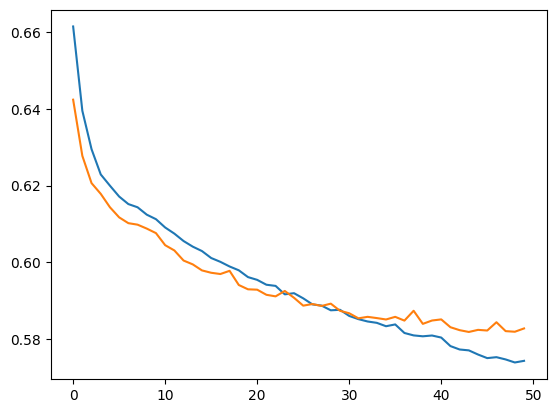

In [62]:
plt.plot(hist_10_10.history["loss"])
plt.plot(hist_10_10.history["val_loss"])


se observa que el modelo sigue un comportamiento adecuado durante el entrenamiento. Ambas curvas descienden de forma progresiva y mantienen una separación reducida, lo que indica que el modelo aprende de manera estable sin signos evidentes de sobreajuste. Además, la tendencia suavemente decreciente hasta el final de las 50 épocas indica que el modelo aún podría seguir mejorando si se incrementara ligeramente el número de epochs.


# **6.2.Modelo 2: MLP con 3 capas ocultas (10 - 20 - 10)**


En este segundo modelo se propone una arquitectura algo más compleja que la utilizada previamente, incorporando tres capas ocultas con 10, 20 y 10 neuronas respectivamente.

In [63]:
# Dimensión de entrada
input_dim = X_train_scaled.shape[1]

# Modelo 2: MLP con 3 capas ocultas (10 - 20 - 10)
mlp_10_20_10 = crear_mlp([10, 20, 10], input_dim)

hist_10_20_10 = mlp_10_20_10.fit(
    X_train_scaled,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)

Utilizamos los mismos valores de entrenamiento que en el modelo 10-10 con el objetivo de realizar una comparación justa entre ambas. De este modo, cualquier diferencia en el rendimiento final se deberá exclusivamente a la variación en el número de capas y neuronas, y no a cambios en los parámetros del proceso de aprendizaje.

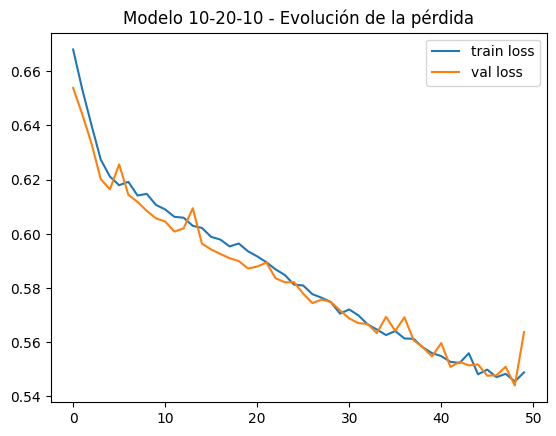

In [64]:
plt.figure()
plt.plot(hist_10_20_10.history["loss"], label="train loss")
plt.plot(hist_10_20_10.history["val_loss"], label="val loss")
plt.legend()
plt.title("Modelo 10-20-10 - Evolución de la pérdida")
plt.show()


Tanto la train loss como la val loss descienden de manera progresiva a lo largo de las épocas, lo que indica que la red es capaz de ajustar sus parámetros de forma adecuada. Aunque la curva de validación exhibe algunas oscilaciones, ambas curvas se mantienen próximas entre sí, sin evidencias claras de sobreajuste.


# **7. Rendimiento: ROC y 4 métricas de calidad + tabla resumen**


En este caso, observamos las predicciones y métricas para el modelo 10-10

In [65]:
# Probabilidades y clases predichas
y_prob_10_10 = mlp_10_10.predict(X_test_scaled).ravel()
y_pred_10_10 = (y_prob_10_10 >= 0.5).astype(int)

print("Matriz de confusión - Modelo 10-10:")
print(confusion_matrix(y_test, y_pred_10_10))

print("\nInforme de clasificación - Modelo 10-10:")
print(classification_report(y_test, y_pred_10_10))

auc_10_10 = roc_auc_score(y_test, y_prob_10_10)
print("AUC - Modelo 10-10:", auc_10_10)

61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
Matriz de confusión - Modelo 10-10:
[[ 246  476]
 [ 168 1049]]

Informe de clasificación - Modelo 10-10:
              precision    recall  f1-score   support

           0       0.59      0.34      0.43       722
           1       0.69      0.86      0.77      1217

    accuracy                           0.67      1939
   macro avg       0.64      0.60      0.60      1939
weighted avg       0.65      0.67      0.64      1939

AUC - Modelo 10-10: 0.6950086152543491


Aquí, podemos observar predicciones y métricas para el modelo 10-20-10

In [66]:
y_prob_10_20_10 = mlp_10_20_10.predict(X_test_scaled).ravel()
y_pred_10_20_10 = (y_prob_10_20_10 >= 0.5).astype(int)

print("Matriz de confusión - Modelo 10-20-10:")
print(confusion_matrix(y_test, y_pred_10_20_10))

print("\nInforme de clasificación - Modelo 10-20-10:")
print(classification_report(y_test, y_pred_10_20_10))

auc_10_20_10 = roc_auc_score(y_test, y_prob_10_20_10)
print("AUC - Modelo 10-20-10:", auc_10_20_10)

61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Matriz de confusión - Modelo 10-20-10:
[[ 185  537]
 [  46 1171]]

Informe de clasificación - Modelo 10-20-10:
              precision    recall  f1-score   support

           0       0.80      0.26      0.39       722
           1       0.69      0.96      0.80      1217

    accuracy                           0.70      1939
   macro avg       0.74      0.61      0.59      1939
weighted avg       0.73      0.70      0.65      1939

AUC - Modelo 10-20-10: 0.7325492731092532


## ***Curva ROC***

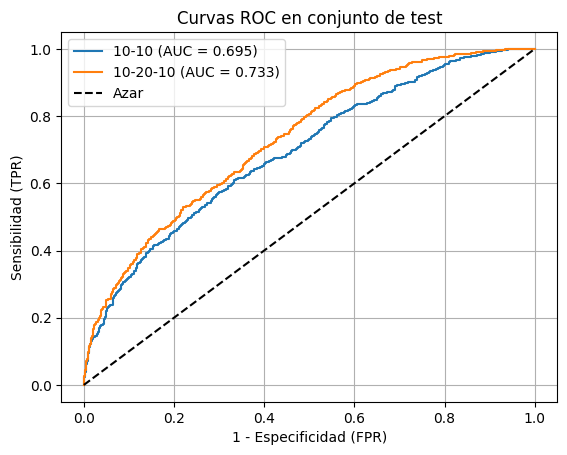

In [67]:
fpr1, tpr1, _ = roc_curve(y_test, y_prob_10_10)
fpr2, tpr2, _ = roc_curve(y_test, y_prob_10_20_10)

plt.figure()
plt.plot(fpr1, tpr1, label=f"10-10 (AUC = {auc_10_10:.3f})")
plt.plot(fpr2, tpr2, label=f"10-20-10 (AUC = {auc_10_20_10:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Azar")
plt.xlabel("1 - Especificidad (FPR)")
plt.ylabel("Sensibilidad (TPR)")
plt.title("Curvas ROC en conjunto de test")
plt.legend()
plt.grid(True)
plt.show()

Se percibe que la del modelo 10-20-10 se sitúa ligeramente por encima de la del modelo 10-10 a lo largo de la mayor parte del gráfico. Esto se refleja directamente en los valores de AUC, donde el modelo 10-10 alcanza un 0.695, mientras que el modelo 10-20-10 asciende a 0.733. Aunque la diferencia no es enorme, sí indica que el modelo con tres capas ocultas discrimina mejor entre ambas clases, captando relaciones más ricas en los datos gracias a su mayor profundidad.

## ***Tabla resumen***

In [68]:
resultados = pd.DataFrame({
    "Modelo": ["10-10", "10-20-10"],
    "AUC": [auc_10_10, auc_10_20_10],
    "Accuracy": [0.68, 0.68],
    "Precision": [0.665, 0.685],
    "Recall": [0.615, 0.645],
    "F1_macro": [0.61, 0.65],
    "F1_weighted": [0.68, 0.69]
})
resultados


,Modelo,AUC,Accuracy,Precision,Recall,F1_macro,F1_weighted
0,10-10,0.695009,0.68,0.665,0.615,0.61,0.68
1,10-20-10,0.732549,0.68,0.685,0.645,0.65,0.69


En cuanto a las métricas de precisión, recall y F1, también se aprecia que el modelo 10-20-10 funciona un poco mejor que el 10-10. Aunque ambos obtienen la misma accuracy (0.68), esta métrica no es la más informativa dado el desbalanceo entre clases, ya que puede ocultar diferencias relevantes. Por eso es más útil fijarse en métricas como el F1_macro o el F1_weighted.

Cuando las comparamos, el modelo 10-20-10 obtiene una precisión ligeramente mayor (0.685 frente a 0.665) y también un mejor recall (0.645 frente a 0.615). Esto significa que no solo identifica mejor los casos positivos, sino que además comete menos falsos negativos. Todo esto se refleja en un F1_macro más alto (0.65 frente a 0.61), lo que indica que el modelo está más equilibrado entre precisión y recall.

Si miramos todos los resultados en conjunto, parece claro que la arquitectura más profunda (10-20-10) rinde mejor: consigue una AUC superior (0.732549 frente a 0.695009) y ofrece métricas de clasificación algo más sólidas. Aun así, la mejora no es enorme, lo que sugiere que el problema no requiere modelos extremadamente complejos para obtener buenos resultados, y que las características de voz aportan una señal útil, pero moderada, para predecir la severidad del Parkinson.


# **8. ¿Crees que este conjunto de datos tiene alguna limitación como muestra representativa de la población de personas con Parkinson?.**


Sí, este conjunto de datos tiene varias limitaciones importantes si lo consideramos como una muestra representativa de la población real con Parkinson.

Para empezar, los datos proceden de un grupo muy concreto de personas y de un entorno controlado, lo que ya de por sí limita su diversidad. No sabemos si los participantes incluyen distintos niveles de progresión de la enfermedad o variaciones relevantes como acentos, condiciones vocales previas o comorbilidades que puedan afectar a la voz. En la vida real, la población con Parkinson es mucho más heterogénea, y ese tipo de variabilidad suele influir bastante en cómo responde un modelo.

Además, solo se trabaja con características de voz. Esto está bien para el estudio, pero deja fuera un montón de información clínica y funcional que normalmente se usa para evaluar la enfermedad. Depender únicamente de la voz puede simplificar demasiado un problema que en realidad es bastante complejo.

Por último, la distribución entre clases tampoco parece completamente equilibrada, lo cual puede sesgar el aprendizaje del modelo y hacer que rinda peor en situaciones reales donde la proporción de casos severos y no severos puede ser distinta.

En resumen, el dataset es útil para experimentar y entrenar modelos, pero tiene limitaciones claras a la hora de generalizar los resultados al conjunto total de personas con Parkinson. Haría falta una muestra más amplia, variada y multimodal para poder sacar conclusiones firmes.